***Exploratory Data Analysis (EDA)***

-เป้าหมายของขั้นตอนนี้คือการ "ทำความเข้าใจข้อมูล" เพื่อพิสูจน์ให้เห็นว่าข้อมูลสังเคราะห์ที่เราสร้างขึ้นมานั้น มีแพทเทิร์นทางสถิติที่สมเหตุสมผลตามสมมติฐานที่เราตั้งไว้ (เช่น คนที่มี DTI สูงจะมีโอกาสเป็นหนี้เสียมากกว่า)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# ตั้งค่าสไตล์กราฟ
sns.set_theme(style="whitegrid")

In [3]:
# โหลดข้อมูล (ใช้ Relative Path ย้อนกลับไป 1 โฟลเดอร์แล้วเข้า data/raw)
df = pd.read_csv('../data/raw/islamic_coop_synthetic_data_v2.csv')

In [4]:
# แสดงผลข้อมูล 5 บรรทัดแรก
display(df.head())

,Age,Monthly_Income,Occupation,Membership_Months,Share_Capital,Financing_Amount,Financing_Tenure_Months,Financing_Type,Business_Distance_km,Own_Capital_Ratio,Guarantor_Type,Historical_Late_Payments,Debt_to_Income_Ratio,Target_NPF
0,58,30795,ข้าราชการ/รัฐวิสาหกิจ,8,6734,141932,12,Business,15,0.42,ข้าราชการ/รัฐวิสาหกิจ,0,0.40,0
1,42,49194,พนักงานเอกชน,8,9322,97498,36,Personal,24,0.35,บุคคลทั่วไป,0,0.06,0
2,21,9433,อาชีพอิสระ/เกษตรกร,1,5555,277455,12,Personal,28,0.20,บุคคลทั่วไป,0,2.57,1
3,63,37658,พนักงานเอกชน,12,1189,356622,48,Personal,10,0.27,ข้าราชการ/รัฐวิสาหกิจ,0,0.24,0
4,63,8267,อาชีพอิสระ/เกษตรกร,5,4890,41551,48,Business,25,0.02,โฉนดที่ดิน,0,0.13,0


ตรวจสอบปัญหาข้อมูลไม่สมดุล (Imbalanced Data)

--- สัดส่วนหนี้เสีย (%) ---
Target_NPF
0    68.99
1    31.01
Name: proportion, dtype: float64


C:\Users\a0864\AppData\Local\Temp\ipykernel_4700\3284397001.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Target_NPF', palette='Set2')


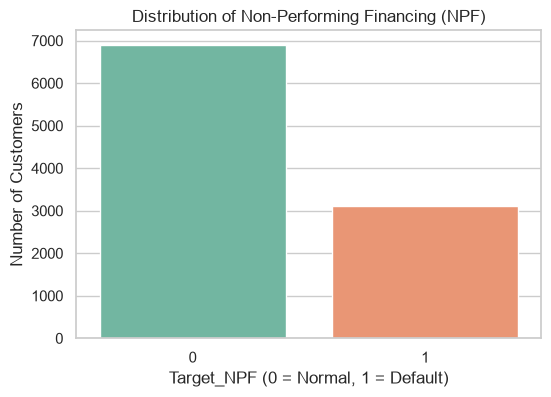

In [5]:
# ดูสัดส่วนลูกค้าปกติ (0) กับหนี้เสีย (1)
npf_counts = df['Target_NPF'].value_counts(normalize=True) * 100
print("--- สัดส่วนหนี้เสีย (%) ---")
print(npf_counts)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Target_NPF', palette='Set2')
plt.title('Distribution of Non-Performing Financing (NPF)')
plt.xlabel('Target_NPF (0 = Normal, 1 = Default)')
plt.ylabel('Number of Customers')
plt.show()

พิสูจน์สมมติฐานทางธุรกิจ (DTI กับ หนี้เสีย)

C:\Users\a0864\AppData\Local\Temp\ipykernel_4700\3996561240.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Target_NPF', y='Debt_to_Income_Ratio', palette='pastel')


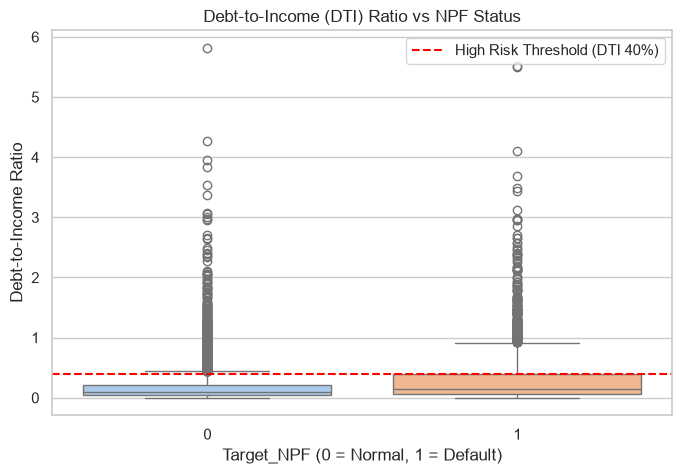

In [6]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Target_NPF', y='Debt_to_Income_Ratio', palette='pastel')
plt.axhline(0.4, color='red', linestyle='--', label='High Risk Threshold (DTI 40%)')
plt.title('Debt-to-Income (DTI) Ratio vs NPF Status')
plt.xlabel('Target_NPF (0 = Normal, 1 = Default)')
plt.ylabel('Debt-to-Income Ratio')
plt.legend()
plt.show()

ดูความสัมพันธ์ของตัวแปรทั้งหมด (Correlation Heatmap)

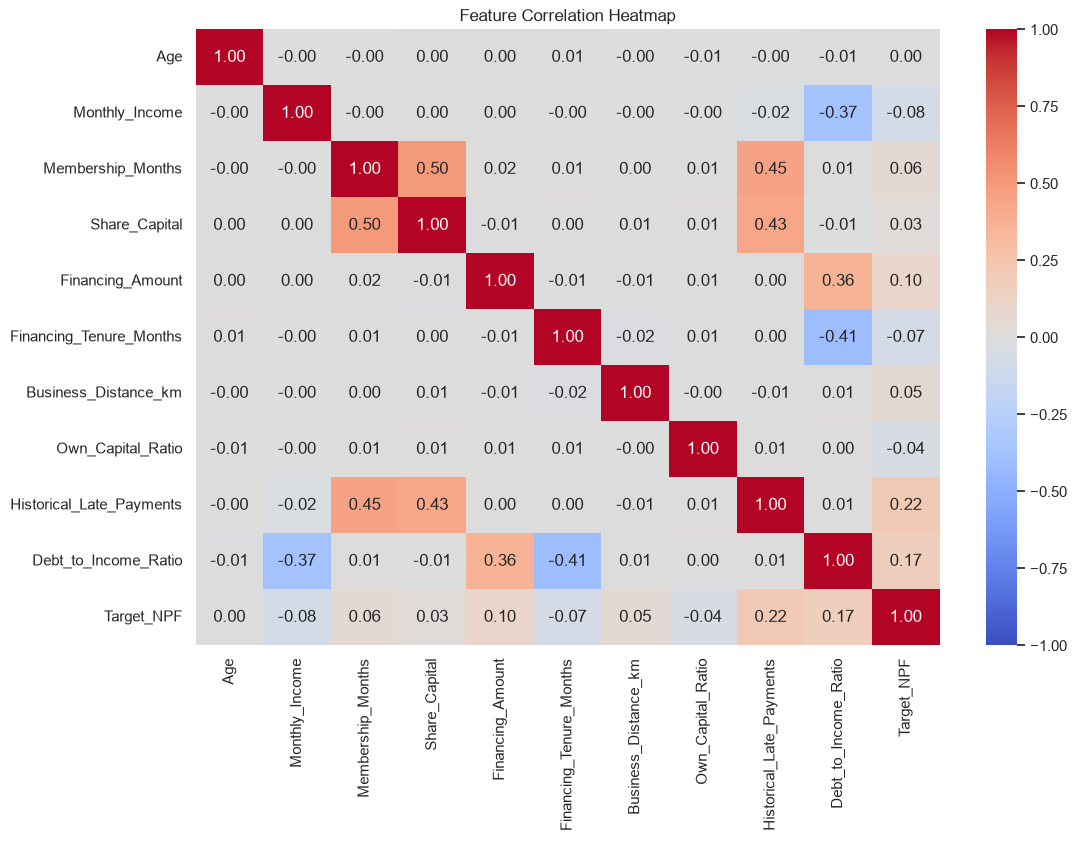

In [7]:
plt.figure(figsize=(12, 8))
# เลือกเฉพาะคอลัมน์ที่เป็นตัวเลขมาหาความสัมพันธ์
numeric_cols = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_cols.corr()

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap')
plt.show()
